In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import matplotlib.pyplot as plt
import pandas as pd
import time
import numpy as np

In [4]:
# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Resize and prepare the images
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load the training and testing data
train_data = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)

test_data = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

train_data = Subset(train_data, range(10000))
test_data = Subset(test_data, range(2000))

# Divide images into batches
train_loader = DataLoader(train_data, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False, num_workers=2)

# Store the names of all classes
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Training images:", len(train_data))
print("Testing images:", len(test_data))
print("Classes:", class_names)


Device: cuda


100%|██████████| 170M/170M [51:49<00:00, 54.8kB/s]


Training images: 10000
Testing images: 2000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [5]:
# Load the pretrained Vision Transformer
vit = models.vit_b_16(weights=models.ViT_B_16_Weights.DEFAULT)

# Freeze the existing layers
for param in vit.parameters():
    param.requires_grad = False

# Change the output layer for 10 classes
vit.heads.head = nn.Linear(vit.heads.head.in_features, 10)
vit = vit.to(device)

# Load the pretrained CNN model
cnn = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze the existing layers
for param in cnn.parameters():
    param.requires_grad = False

# Change the output layer for 10 classes
cnn.fc = nn.Linear(cnn.fc.in_features, 10)
cnn = cnn.to(device)

print("ViT and CNN models loaded successfully")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 161MB/s]


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 60.7MB/s]


ViT and CNN models loaded successfully


In [6]:
# Train the model and calculate training time
def train_model(model, train_loader, epochs=3):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=0.001
    )

    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        # Train using batches of images
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        # Display loss and training accuracy
        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {running_loss/len(train_loader):.4f}, "
            f"Accuracy: {100*correct/total:.2f}%"
        )

    training_time = time.time() - start_time
    return training_time

In [7]:
# Train the Vision Transformer
print("Training Vision Transformer (ViT)")
vit_time = train_model(vit, train_loader, epochs=3)

Training Vision Transformer (ViT)
Epoch [1/3], Loss: 0.3577, Accuracy: 90.65%
Epoch [2/3], Loss: 0.1643, Accuracy: 95.02%
Epoch [3/3], Loss: 0.1299, Accuracy: 95.81%


In [8]:
# Train the CNN using the same dataset
print("Training CNN (ResNet-18)")
cnn_time = train_model(cnn, train_loader, epochs=3)

Training CNN (ResNet-18)
Epoch [1/3], Loss: 1.1493, Accuracy: 63.57%
Epoch [2/3], Loss: 0.7532, Accuracy: 74.77%
Epoch [3/3], Loss: 0.6795, Accuracy: 76.80%


In [9]:
# Test the model and calculate performance scores
def evaluate_model(model, test_loader):
    model.eval()
    actual = []
    predicted_labels = []

    # Predict the class of each test image
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            actual.extend(labels.numpy())
            predicted_labels.extend(predicted.cpu().numpy())

    # Calculate classification metrics
    accuracy = accuracy_score(actual, predicted_labels)
    precision = precision_score(
        actual, predicted_labels, average="macro", zero_division=0
    )
    recall = recall_score(
        actual, predicted_labels, average="macro", zero_division=0
    )
    f1 = f1_score(
        actual, predicted_labels, average="macro", zero_division=0
    )

    return accuracy, precision, recall, f1, actual, predicted_labels

# Evaluate ViT and CNN
vit_results = evaluate_model(vit, test_loader)
cnn_results = evaluate_model(cnn, test_loader)

# Display detailed classification reports
print("ViT Classification Report")
print(classification_report(
    vit_results[4], vit_results[5],
    target_names=class_names, zero_division=0
))

print("CNN Classification Report")
print(classification_report(
    cnn_results[4], cnn_results[5],
    target_names=class_names, zero_division=0
))

ViT Classification Report
              precision    recall  f1-score   support

    airplane       0.96      0.94      0.95       196
  automobile       0.97      0.99      0.98       198
        bird       0.94      0.93      0.94       195
         cat       0.91      0.89      0.90       199
        deer       0.96      0.94      0.95       198
         dog       0.92      0.94      0.93       185
        frog       0.96      0.97      0.96       216
       horse       0.94      0.97      0.96       193
        ship       0.99      0.97      0.98       217
       truck       0.96      0.97      0.97       203

    accuracy                           0.95      2000
   macro avg       0.95      0.95      0.95      2000
weighted avg       0.95      0.95      0.95      2000

CNN Classification Report
              precision    recall  f1-score   support

    airplane       0.76      0.75      0.75       196
  automobile       0.84      0.91      0.87       198
        bird       0.74   

                 Metric        ViT  CNN (ResNet-18)
               Accuracy   0.951500         0.774000
              Precision   0.950901         0.775951
                 Recall   0.951110         0.772693
               F1-Score   0.950920         0.771319
Training Time (seconds) 437.025948        70.943579


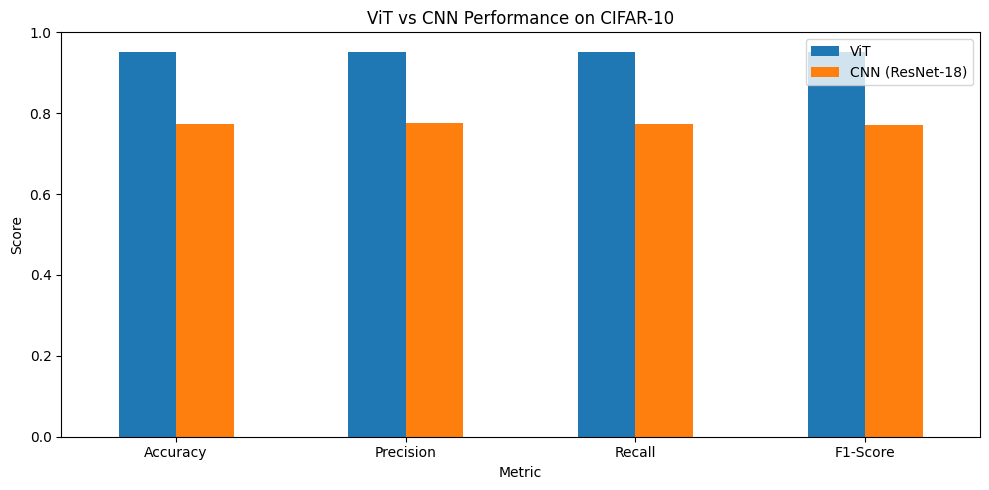

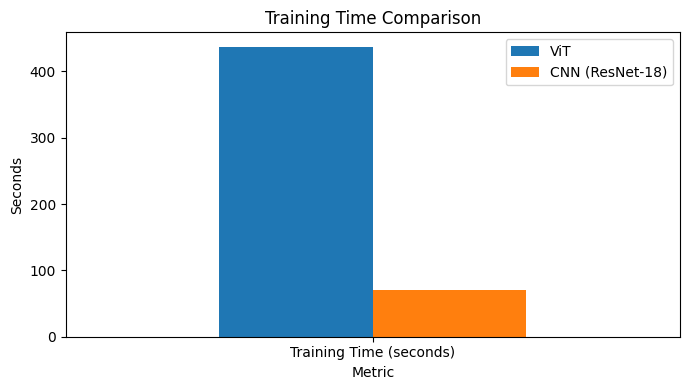

In [10]:
# Store the results in a table
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "Training Time (seconds)"],
    "ViT": [
        vit_results[0], vit_results[1], vit_results[2],
        vit_results[3], vit_time
    ],
    "CNN (ResNet-18)": [
        cnn_results[0], cnn_results[1], cnn_results[2],
        cnn_results[3], cnn_time
    ]
})

# Print the comparison table
print(results.to_string(index=False))

# Compare classification scores using a graph
metrics = results.iloc[:4]
metrics.set_index("Metric").plot(kind="bar", figsize=(10, 5))

plt.title("ViT vs CNN Performance on CIFAR-10")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

# Compare training time
results.set_index("Metric").loc[
    ["Training Time (seconds)"]
].plot(kind="bar", figsize=(7, 4))

plt.title("Training Time Comparison")
plt.ylabel("Seconds")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

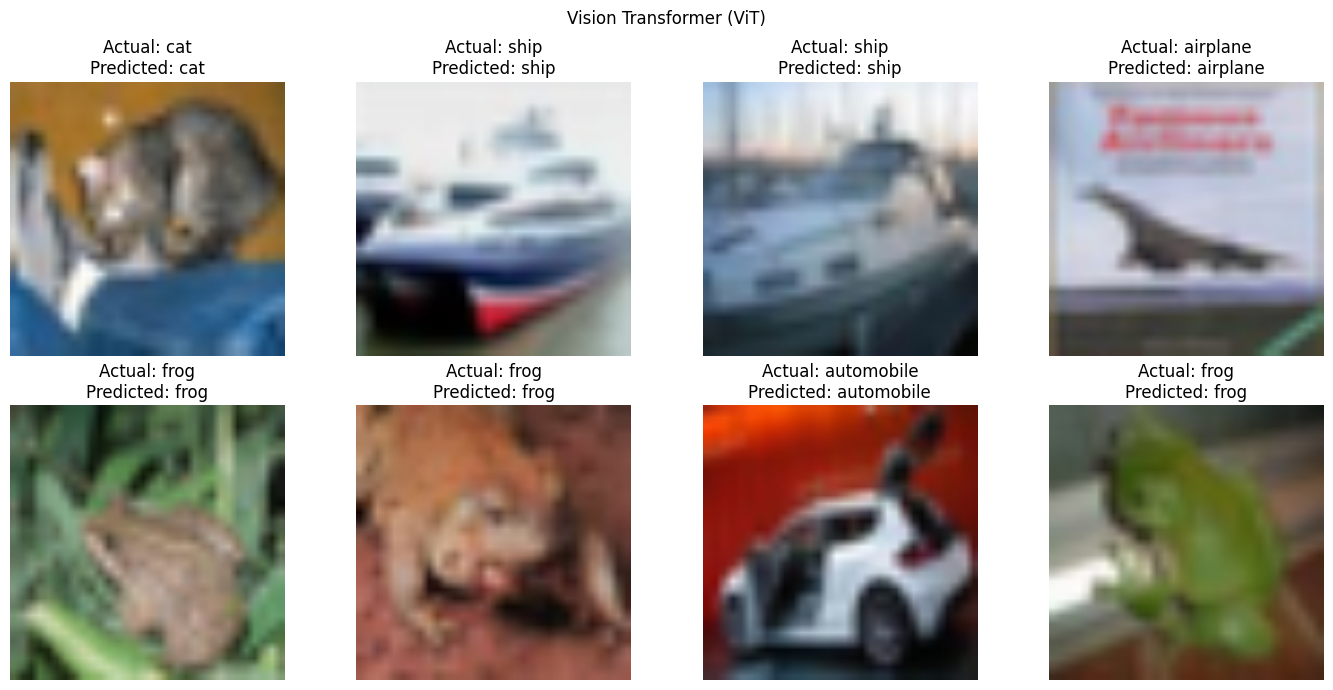

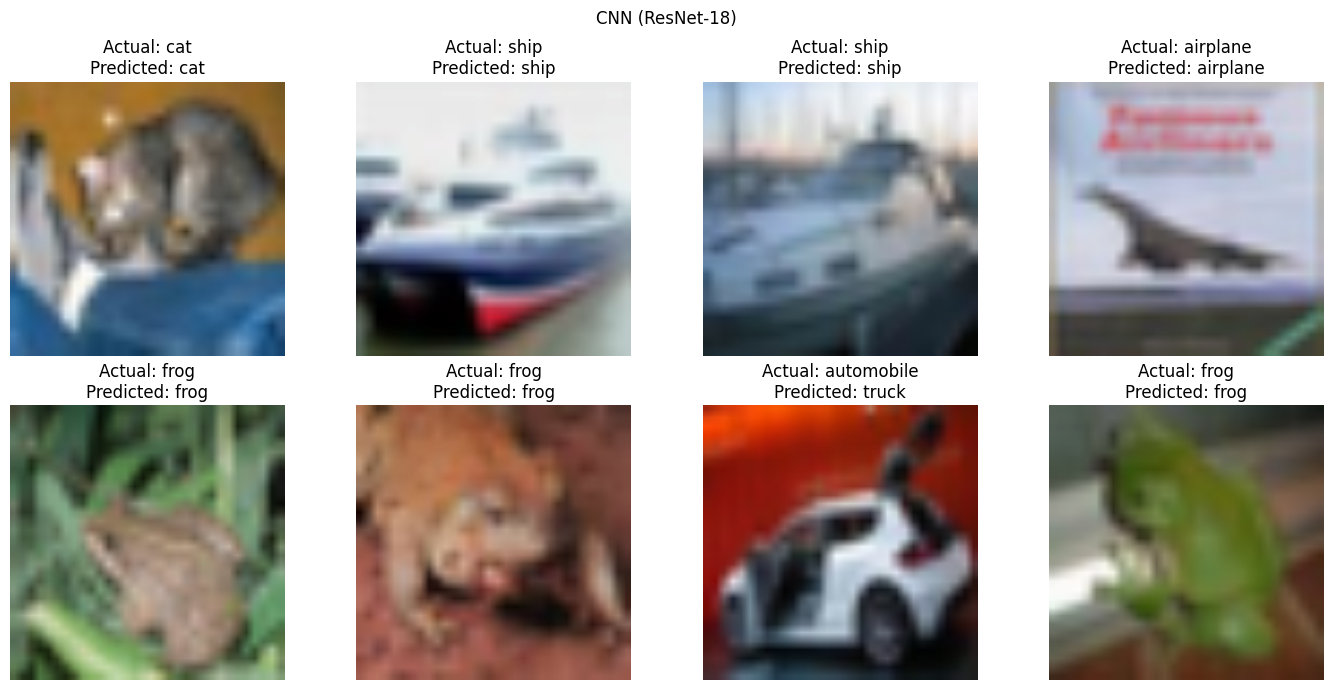

In [11]:
# Show actual and predicted labels for sample images
def show_predictions(model, dataset, model_name, count=8):
    model.eval()
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))

    for i, ax in enumerate(axes.flat):
        image, label = dataset[i]

        # Predict the class of the image
        with torch.no_grad():
            output = model(image.unsqueeze(0).to(device))
            prediction = output.argmax(dim=1).item()

        # Convert the image back to normal colours
        display_image = image.permute(1, 2, 0).numpy()
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        display_image = np.clip(display_image * std + mean, 0, 1)

        # Display the image and its labels
        ax.imshow(display_image)
        ax.set_title(
            f"Actual: {class_names[label]}\nPredicted: {class_names[prediction]}"
        )
        ax.axis("off")

    plt.suptitle(model_name)
    plt.tight_layout()
    plt.show()

# Display predictions from both models
show_predictions(vit, test_data, "Vision Transformer (ViT)")
show_predictions(cnn, test_data, "CNN (ResNet-18)")